# ENGE707 Kaggle Competition: Data Preprocessing and Pipeline Preparation

## Cat and Dog Facial Feature Classification

This notebook prepares the competition images for later CNN training.

It completes the following tasks:

1. Encode the eight class names as numerical labels.
2. Group exact duplicate training images.
3. Divide the labelled data into training and validation subsets.
4. Keep similar class percentages in both subsets.
5. Prevent duplicate images from appearing in both subsets.
6. Convert images consistently to RGB.
7. Pad and resize images to `224 × 224`.
8. Normalise the image tensors.
9. Apply random changes only to training images.
10. Create PyTorch datasets and data loaders.
11. Verify the shape and contents of one training batch.
12. Prepare the test dataset without using it for model selection.

The original JPG and CSV files are read but never modified. Image transformations happen temporarily in memory.

## 1. Import the Required Libraries

This notebook introduces PyTorch because the data is now being prepared for CNN training.

The main libraries are:

- `pandas` and `numpy` for tables and numerical operations.
- `matplotlib` for report figures.
- `PIL` for opening and padding images.
- `scikit-learn` for the training-validation split.
- `torch` for tensors and reproducibility settings.
- `torchvision.transforms` for resizing, augmentation, tensor conversion, and normalisation.
- `Dataset` for defining how one image is loaded.
- `DataLoader` for loading images in batches.

No CNN is created or trained in this notebook.

In [1]:
# Imports the libraries used for preprocessing and splitting the data
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.model_selection import StratifiedGroupKFold

## 2. Set Reproducibility Values

A fixed random seed makes the split and random selections repeatable.

The same seed will be used by:

- Python;
- NumPy;
- PyTorch;
- the splitting method; and
- the training data loader.

The input image size is set to `224 × 224`. This size can be used by both the planned custom CNN and pretrained ResNet18 model.

In [2]:
# Sets the image size and random seeds used by the pipeline
RANDOM_SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
VALIDATION_FRACTION = 0.20

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)
print("Input image size:", f"{IMAGE_SIZE} × {IMAGE_SIZE}")
print("Batch size:", BATCH_SIZE)
print("Planned validation fraction:", VALIDATION_FRACTION)
print("PyTorch version:", torch.__version__)

Random seed: 42
Input image size: 224 × 224
Batch size: 32
Planned validation fraction: 0.2
PyTorch version: 2.14.1


## 3. Locate the Dataset and Output Folders

The notebook may be opened from either the main project folder or the `notebooks` folder.

The code finds the project folder automatically.

The original dataset is read from `data/`. New results are written to:

- `splits/`
- `outputs/figures/`
- `outputs/preprocessing/`

No output is written into the original dataset folders.

In [3]:
# Finds the original dataset and creates folders for generated evidence
possible_project_roots = [
    Path.cwd(),
    Path.cwd().parent,
]

PROJECT_ROOT = next(
    (
        folder
        for folder in possible_project_roots
        if (folder / "data" / "train_labels.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "The project folder could not be found. "
        "Check the notebook location and dataset structure."
    )

DATA_DIR = PROJECT_ROOT / "data"
TRAIN_IMAGE_DIR = DATA_DIR / "train" / "train"
TEST_IMAGE_DIR = DATA_DIR / "test" / "test"

TRAIN_LABELS_PATH = DATA_DIR / "train_labels.csv"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

DUPLICATE_RESULTS_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "quality_checks"
    / "exact_duplicate_images.csv"
)

SPLIT_DIR = PROJECT_ROOT / "splits"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
PREPROCESSING_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "preprocessing"
)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    TRAIN_IMAGE_DIR,
    TEST_IMAGE_DIR,
    TRAIN_LABELS_PATH,
    SAMPLE_SUBMISSION_PATH,
    DUPLICATE_RESULTS_PATH,
]

missing_paths = [
    path for path in required_paths if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "The following required paths are missing:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

print("Project folder:", PROJECT_ROOT)
print("Training images:", TRAIN_IMAGE_DIR)
print("Test images:", TEST_IMAGE_DIR)
print("Split output:", SPLIT_DIR)
print("Preprocessing output:", PREPROCESSING_OUTPUT_DIR)

Project folder: /Users/fatehbhular/ENSE707-Kaggle-Competition
Training images: /Users/fatehbhular/ENSE707-Kaggle-Competition/data/train/train
Test images: /Users/fatehbhular/ENSE707-Kaggle-Competition/data/test/test
Split output: /Users/fatehbhular/ENSE707-Kaggle-Competition/splits
Preprocessing output: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/preprocessing


## 4. Load the Training Labels and Submission Structure

The training-label CSV contains the known class for every training image.

The sample-submission CSV contains the test IDs in the order required by Kaggle.

Image IDs are loaded as text so leading zeros can be preserved when filenames are created.

In [4]:
# Reads the training labels and the required submission order
train_labels = pd.read_csv(
    TRAIN_LABELS_PATH,
    dtype={"image_id": "string", "class": "string"},
)

sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": "string", "class": "string"},
)


def id_to_filename(image_id):
    """Convert an image ID into its five-digit JPG filename."""
    image_stem = Path(str(image_id)).stem
    return f"{int(image_stem):05d}.jpg"


train_labels["filename"] = (
    train_labels["image_id"].apply(id_to_filename)
)

sample_submission["filename"] = (
    sample_submission["image_id"].apply(id_to_filename)
)

print("Labelled images:", f"{len(train_labels):,}")
print("Test images:", f"{len(sample_submission):,}")

display(train_labels.head())
display(sample_submission.head())

Labelled images: 63,660
Test images: 29,443


,image_id,class,filename
0,00001,DogEye,00001.jpg
1,00002,DogMouth,00002.jpg
2,00003,DogFace,00003.jpg
3,00004,DogNose,00004.jpg
4,00005,DogNose,00005.jpg


,image_id,class,filename
0,1,DogEye,00001.jpg
1,2,CatNose,00002.jpg
2,3,CatNose,00003.jpg
3,4,DogFace,00004.jpg
4,5,DogMouth,00005.jpg


## 5. Define the Official Class Mapping

CNNs work with numerical labels rather than class names.

Each official class is assigned a number from 0 to 7. A fixed mapping is used so that:

- the same class always receives the same number;
- results can be reproduced;
- and prediction numbers can later be changed back into the exact Kaggle class names.

In [5]:
# Assigns a fixed number to each class and saves the mapping
CLASS_NAMES = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose",
]

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

INDEX_TO_CLASS = {
    index: class_name
    for class_name, index in CLASS_TO_INDEX.items()
}

unexpected_classes = (
    set(train_labels["class"]) - set(CLASS_NAMES)
)

if unexpected_classes:
    raise ValueError(
        f"Unexpected classes found: {unexpected_classes}"
    )

train_labels["label_index"] = (
    train_labels["class"].map(CLASS_TO_INDEX)
)

label_mapping = pd.DataFrame(
    {
        "class": CLASS_NAMES,
        "label_index": [
            CLASS_TO_INDEX[class_name]
            for class_name in CLASS_NAMES
        ],
    }
)

display(label_mapping)

# Saves the table as a CSV file for later notebooks or report evidence
label_mapping.to_csv(
    PREPROCESSING_OUTPUT_DIR / "label_mapping.csv",
    index=False,
)

,class,label_index
0,CatEye,0
1,DogEye,1
2,CatFace,2
3,DogFace,3
4,CatMouth,4
5,DogMouth,5
6,CatNose,6
7,DogNose,7


## 6. Create Duplicate Group Identifiers

Task 1 found exact duplicate images in the labelled training data.

If one copy is placed in training and another identical copy is placed in validation, the validation result could be misleading. The model may appear to recognise a new image even though it has already seen an identical copy.

Images with the same SHA-256 hash are therefore given the same group identifier.

Every image without an exact duplicate receives its own unique group identifier.

In [6]:
# Gives exact duplicate images a shared group identifier
duplicate_results = pd.read_csv(
    DUPLICATE_RESULTS_PATH,
    dtype={
        "split": "string",
        "filename": "string",
        "sha256": "string",
    },
)

training_duplicates = duplicate_results[
    duplicate_results["split"] == "train"
].copy()

duplicate_hash_by_filename = (
    training_duplicates
    .set_index("filename")["sha256"]
    .to_dict()
)


def create_group_id(filename):
    """
    Use the shared hash for duplicate files.

    Images without duplicates receive a group based on their filename.
    """
    if filename in duplicate_hash_by_filename:
        return f"duplicate_{duplicate_hash_by_filename[filename]}"

    return f"unique_{filename}"


train_labels["group_id"] = (
    train_labels["filename"].apply(create_group_id)
)

duplicate_label_counts = (
    train_labels
    .groupby("group_id")["class"]
    .nunique()
)

conflicting_groups = duplicate_label_counts[
    duplicate_label_counts > 1
]

if len(conflicting_groups) > 0:
    raise ValueError(
        "At least one duplicate group contains different labels."
    )

duplicate_group_sizes = (
    train_labels
    .groupby("group_id")
    .size()
)

repeated_groups = duplicate_group_sizes[
    duplicate_group_sizes > 1
]

print(
    "Exact duplicate groups in labelled data:",
    len(repeated_groups),
)

print(
    "Images belonging to duplicate groups:",
    int(repeated_groups.sum()),
)

print(
    "Duplicate groups with conflicting labels:",
    len(conflicting_groups),
)

Exact duplicate groups in labelled data: 15
Images belonging to duplicate groups: 30
Duplicate groups with conflicting labels: 0


## 7. Create the Stratified 80/20 Split

The labelled data is divided into:

- a training subset used to teach the model; and
- a validation subset used to measure performance on unseen labelled images.

`StratifiedGroupKFold` is used because it provides two protections:

1. Stratification keeps the class percentages similar.
2. Grouping keeps exact duplicate images in the same subset.

Five folds are used. One fold becomes validation and the other four become training, producing an approximately 80/20 split.

In [7]:
# Creates an 80 percent training split and a 20 percent validation split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED,
)

split_indices = list(
    splitter.split(
        X=train_labels["filename"],
        y=train_labels["class"],
        groups=train_labels["group_id"],
    )
)

# Use the first reproducible fold
training_indices, validation_indices = split_indices[0]

training_split = (
    train_labels
    .iloc[training_indices]
    .copy()
    .reset_index(drop=True)
)

validation_split = (
    train_labels
    .iloc[validation_indices]
    .copy()
    .reset_index(drop=True)
)

training_percentage = (
    len(training_split) / len(train_labels) * 100
)

validation_percentage = (
    len(validation_split) / len(train_labels) * 100
)

print("Complete labelled dataset:", f"{len(train_labels):,}")
print(
    "Training subset:",
    f"{len(training_split):,}",
    f"({training_percentage:.2f}%)",
)
print(
    "Validation subset:",
    f"{len(validation_split):,}",
    f"({validation_percentage:.2f}%)",
)

Complete labelled dataset: 63,660
Training subset: 50,928 (80.00%)
Validation subset: 12,732 (20.00%)


## 8. Verify the Split and Check for Leakage

The following checks confirm that:

- no image ID appears in both subsets;
- no duplicate group appears in both subsets;
- every class appears in both subsets;
- and the two subsets contain all labelled images exactly once.

The notebook stops with an error if any important check fails.

In [8]:
# Checks that image identifiers and duplicate groups do not cross the split
shared_image_ids = (
    set(training_split["image_id"])
    & set(validation_split["image_id"])
)

shared_group_ids = (
    set(training_split["group_id"])
    & set(validation_split["group_id"])
)

training_classes = set(training_split["class"])
validation_classes = set(validation_split["class"])
expected_classes = set(CLASS_NAMES)

all_images_accounted_for = (
    len(training_split) + len(validation_split)
    == len(train_labels)
)

split_checks = pd.DataFrame(
    {
        "check": [
            "Shared image IDs",
            "Shared duplicate groups",
            "All classes in training",
            "All classes in validation",
            "All labelled images accounted for",
        ],
        "result": [
            len(shared_image_ids),
            len(shared_group_ids),
            training_classes == expected_classes,
            validation_classes == expected_classes,
            all_images_accounted_for,
        ],
        "expected": [
            0,
            0,
            True,
            True,
            True,
        ],
    }
)

display(split_checks)

assert len(shared_image_ids) == 0
assert len(shared_group_ids) == 0
assert training_classes == expected_classes
assert validation_classes == expected_classes
assert all_images_accounted_for

print("All split and leakage checks passed.")

# Saves the table as a CSV file for later notebooks or report evidence
split_checks.to_csv(
    PREPROCESSING_OUTPUT_DIR
    / "split_validation_checks.csv",
    index=False,
)

,check,result,expected
0,Shared image IDs,0,0
1,Shared duplicate groups,0,0
2,All classes in training,True,True
3,All classes in validation,True,True
4,All labelled images accounted for,True,True


All split and leakage checks passed.


## 9. Compare Class Distribution Across the Splits

A suitable stratified split should keep similar class percentages in:

- the complete labelled dataset;
- the training subset; and
- the validation subset.

The following table and graph provide evidence that the class distribution was preserved.

In [9]:
# Calculates class counts and percentages for each subset
def calculate_class_distribution(dataframe, subset_name):
    """Calculate image counts and percentages for one subset."""
    distribution = (
        dataframe["class"]
        .value_counts()
        .reindex(CLASS_NAMES)
        .fillna(0)
        .astype(int)
        .rename("images")
        .reset_index()
        .rename(columns={"index": "class"})
    )

    distribution["percentage"] = (
        distribution["images"]
        / distribution["images"].sum()
        * 100
    )

    distribution["subset"] = subset_name

    return distribution


complete_distribution = calculate_class_distribution(
    train_labels,
    "Complete labelled data",
)

training_distribution = calculate_class_distribution(
    training_split,
    "Training",
)

validation_distribution = calculate_class_distribution(
    validation_split,
    "Validation",
)

split_distribution = pd.concat(
    [
        complete_distribution,
        training_distribution,
        validation_distribution,
    ],
    ignore_index=True,
)

display(
    split_distribution.pivot(
        index="class",
        columns="subset",
        values=["images", "percentage"],
    ).round(2)
)

# Saves the table as a CSV file for later notebooks or report evidence
split_distribution.to_csv(
    PREPROCESSING_OUTPUT_DIR
    / "split_class_distribution.csv",
    index=False,
)

images                                 percentage  \
subset   Complete labelled data Training Validation Complete labelled data   
class                                                                        
CatEye                  13884.0  11107.0     2777.0                  21.81   
CatFace                  6942.0   5553.0     1389.0                  10.90   
CatMouth                 6942.0   5554.0     1388.0                  10.90   
CatNose                  6942.0   5554.0     1388.0                  10.90   
DogEye                  11580.0   9264.0     2316.0                  18.19   
DogFace                  5790.0   4632.0     1158.0                   9.10   
DogMouth                 5790.0   4632.0     1158.0                   9.10   
DogNose                  5790.0   4632.0     1158.0                   9.10   

                              
subset   Training Validation  
class                         
CatEye      21.81      21.81  
CatFace     10.90      10.91  
CatMouth    10.91      10.90  
CatNose     10.91      10.90  
DogEye      18.19      18.19  
DogFace      9.10       9.10  
DogMouth     9.10       9.10  
DogNose      9.10       9.10

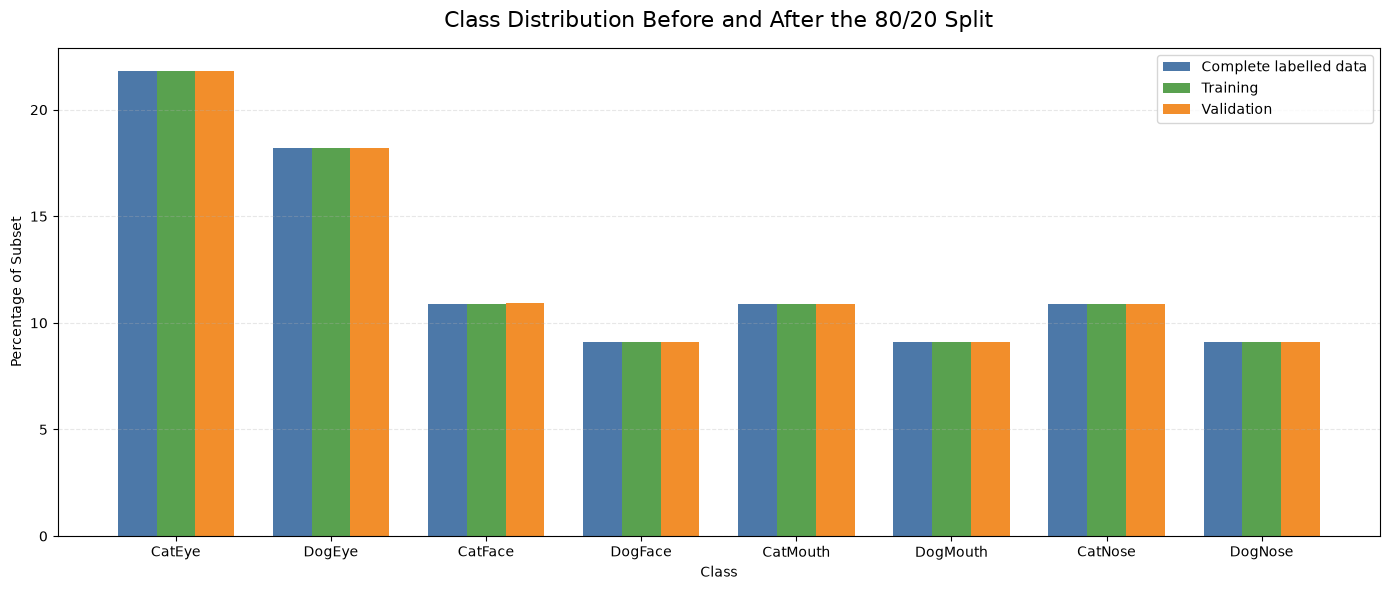

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_07_split_class_distribution.png


In [10]:
# Plots the class proportions to compare the saved subsets
figure_data = (
    split_distribution
    .pivot(
        index="class",
        columns="subset",
        values="percentage",
    )
    .reindex(CLASS_NAMES)
)

x_positions = np.arange(len(CLASS_NAMES))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    x_positions - bar_width,
    figure_data["Complete labelled data"],
    width=bar_width,
    label="Complete labelled data",
    color="#4C78A8",
)

ax.bar(
    x_positions,
    figure_data["Training"],
    width=bar_width,
    label="Training",
    color="#59A14F",
)

ax.bar(
    x_positions + bar_width,
    figure_data["Validation"],
    width=bar_width,
    label="Validation",
    color="#F28E2B",
)

ax.set_title(
    "Class Distribution Before and After the 80/20 Split",
    fontsize=16,
    pad=15,
)

ax.set_xlabel("Class")
ax.set_ylabel("Percentage of Subset")
ax.set_xticks(x_positions)
ax.set_xticklabels(CLASS_NAMES)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()

split_figure_path = (
    FIGURE_DIR
    / "figure_07_split_class_distribution.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    split_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", split_figure_path)

### Interpretation of the Split

Use the table and graph to confirm:

- whether the split is close to 80/20;
- whether every class appears in both subsets;
- whether the class percentages remain similar;
- and whether any duplicate group crosses the split.

The exact numbers produced here should later be reported in Task 2 of the written report.

## 10. Save the Training and Validation Splits

The split is saved so every later model uses exactly the same images.

Using one saved split makes model comparisons fair and reproducible.

The saved CSV files contain:

- image ID;
- class name;
- filename;
- encoded label; and
- duplicate group identifier.

The original `train_labels.csv` file is not changed.

In [11]:
# Saves the split tables without changing the original image files
split_columns = [
    "image_id",
    "class",
    "filename",
    "label_index",
    "group_id",
]

training_split_path = SPLIT_DIR / "train_split.csv"
validation_split_path = SPLIT_DIR / "validation_split.csv"

# Saves the table as a CSV file for later notebooks or report evidence
training_split[split_columns].to_csv(
    training_split_path,
    index=False,
)

# Saves the table as a CSV file for later notebooks or report evidence
validation_split[split_columns].to_csv(
    validation_split_path,
    index=False,
)

print("Training split saved to:", training_split_path)
print("Validation split saved to:", validation_split_path)

Training split saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/splits/train_split.csv
Validation split saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/splits/validation_split.csv


## 11. Define Square Padding

The original images use many different widths and heights.

Directly stretching every image into a square could change the shape of an eye, nose, mouth, or face. Instead, padding is added around the shorter side to make the image square.

The square image is then resized to `224 × 224`.

Padding and resizing happen temporarily in memory. The original JPG file is not changed.

In [12]:
# Defines how to add borders without cutting or stretching the image
class SquarePad:
    """Add equal padding around the shorter sides of an image."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size

        largest_side = max(width, height)

        horizontal_padding = largest_side - width
        vertical_padding = largest_side - height

        left_padding = horizontal_padding // 2
        right_padding = horizontal_padding - left_padding

        top_padding = vertical_padding // 2
        bottom_padding = vertical_padding - top_padding

        return ImageOps.expand(
            image,
            border=(
                left_padding,
                top_padding,
                right_padding,
                bottom_padding,
            ),
            fill=self.fill,
        )

## 12. Define Training, Validation, and Test Transformations

All images receive the same essential preparation:

1. Convert to RGB when opened.
2. Pad to a square.
3. Resize to `224 × 224`.
4. Convert to a PyTorch tensor.
5. Normalise using ImageNet values.

Training images also receive small random changes:

- a possible horizontal flip;
- a rotation of up to 10 degrees;
- and small brightness, contrast, and colour changes.

These changes help the model learn normal visual variation.

Validation and test images do not receive random changes. This ensures that validation remains a fair and repeatable performance check.

In [13]:
# Defines training changes and fixed validation and test preprocessing
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

training_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=10,
            interpolation=InterpolationMode.BILINEAR,
            fill=(0, 0, 0),
        ),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.10,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

evaluation_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

display_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
    ]
)

print(training_transform)
print()
print(evaluation_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=(0, 0, 0))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 13. Display Original and Resized Images

This figure compares original training images with their padded and resized versions.

The comparison demonstrates that:

- images begin with different dimensions;
- padding makes each image square;
- and every processed image becomes `224 × 224`.

The selected examples come from different classes and are chosen reproducibly.

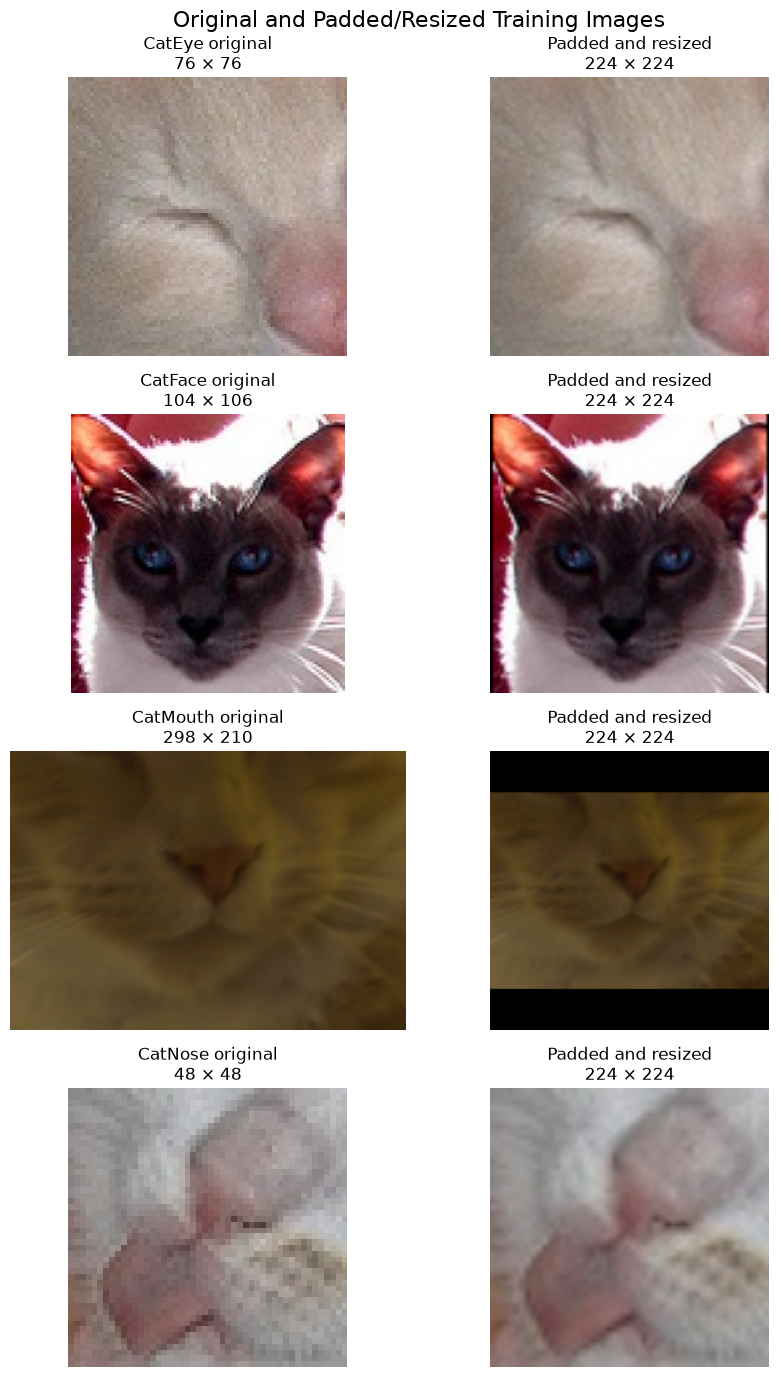

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_08_resize_and_padding_examples.png


In [14]:
# Shows the original images beside their padded and resized versions
resize_example_rows = (
    training_split
    .groupby("class", group_keys=False)
    .sample(
        n=1,
        random_state=RANDOM_SEED,
    )
    .head(4)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    nrows=len(resize_example_rows),
    ncols=2,
    figsize=(9, 14),
)

for row_number, row in resize_example_rows.iterrows():
    image_path = TRAIN_IMAGE_DIR / row["filename"]

    with Image.open(image_path) as image:
        original_image = image.convert("RGB")
        processed_image = display_transform(original_image)

    axes[row_number, 0].imshow(original_image)
    axes[row_number, 0].set_title(
        f"{row['class']} original\n"
        f"{original_image.width} × {original_image.height}"
    )
    axes[row_number, 0].axis("off")

    axes[row_number, 1].imshow(processed_image)
    axes[row_number, 1].set_title(
        f"Padded and resized\n"
        f"{processed_image.width} × {processed_image.height}"
    )
    axes[row_number, 1].axis("off")

plt.suptitle(
    "Original and Padded/Resized Training Images",
    fontsize=16,
)

plt.tight_layout()

resize_figure_path = (
    FIGURE_DIR
    / "figure_08_resize_and_padding_examples.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    resize_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", resize_figure_path)

## 14. Display Training Augmentation

The same training image can appear slightly different each time it is loaded.

This figure displays several randomly transformed versions of selected training images.

The animal and facial-region label remain unchanged. Only the visual presentation changes.

Augmentation is not saved over the original image.

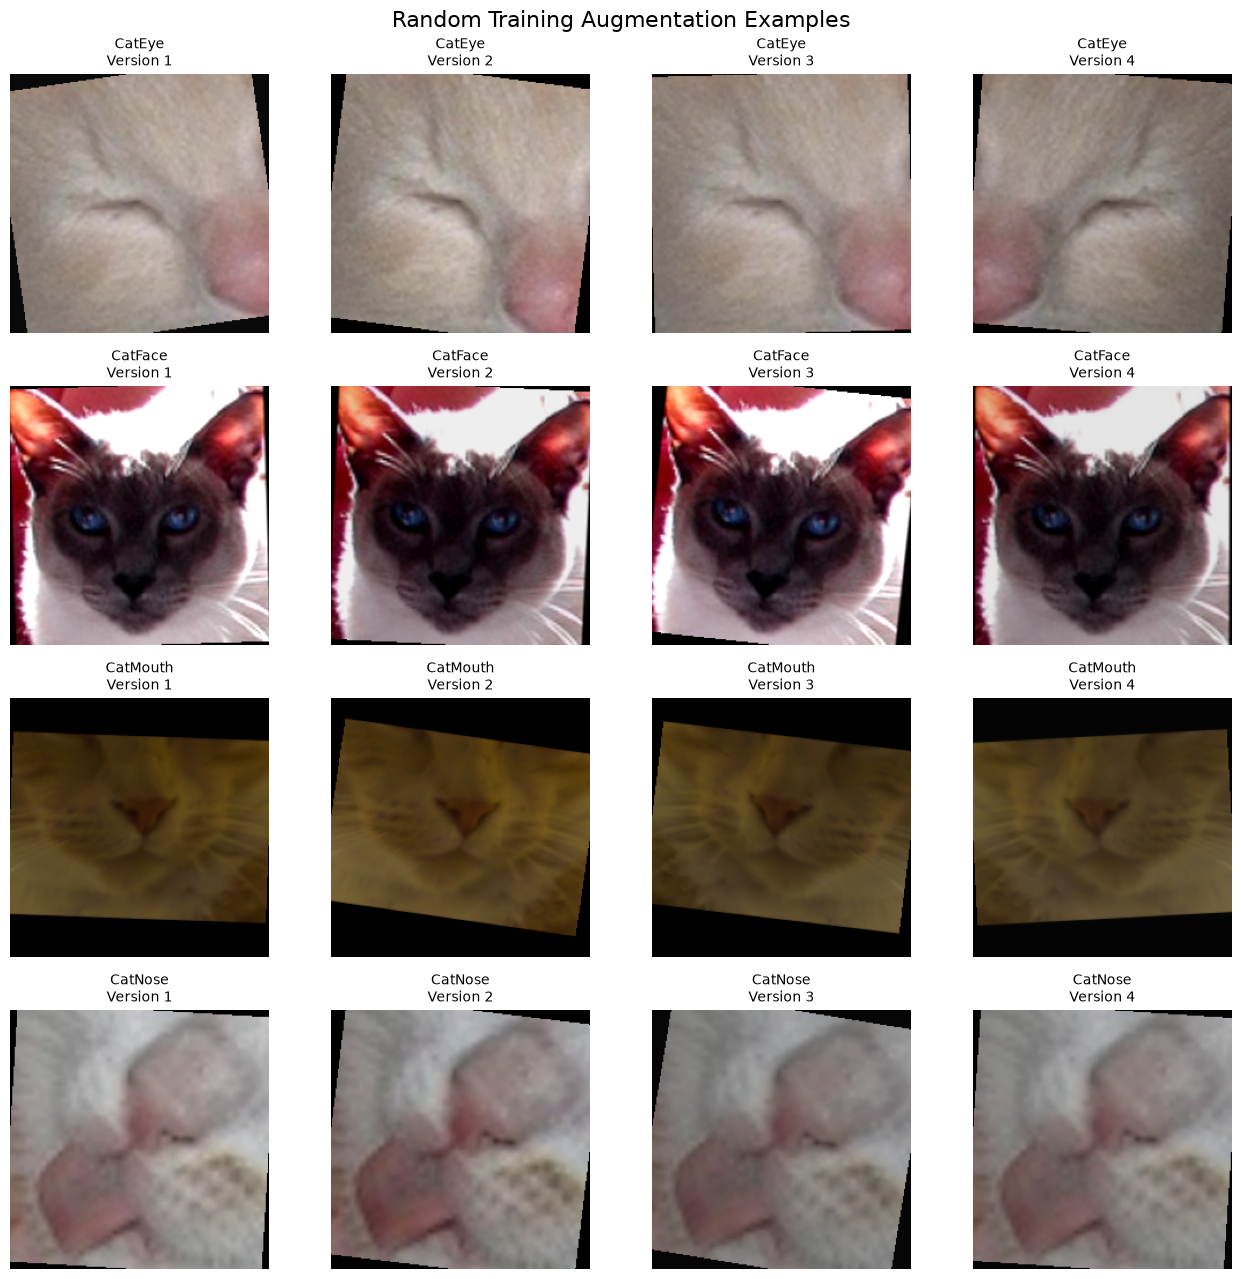

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_09_training_augmentation.png


In [15]:
# Shows examples of the random changes applied to training images
mean_tensor = torch.tensor(
    IMAGENET_MEAN
).view(3, 1, 1)

std_tensor = torch.tensor(
    IMAGENET_STD
).view(3, 1, 1)


def tensor_to_display_image(image_tensor):
    """Reverse normalisation so a tensor can be displayed."""
    restored_tensor = (
        image_tensor.cpu() * std_tensor + mean_tensor
    )

    restored_tensor = restored_tensor.clamp(0, 1)

    return restored_tensor.permute(1, 2, 0).numpy()


augmentation_example_rows = (
    training_split
    .groupby("class", group_keys=False)
    .sample(
        n=1,
        random_state=RANDOM_SEED,
    )
    .head(4)
    .reset_index(drop=True)
)

AUGMENTED_VERSIONS = 4

fig, axes = plt.subplots(
    nrows=len(augmentation_example_rows),
    ncols=AUGMENTED_VERSIONS,
    figsize=(13, 13),
)

for row_number, row in augmentation_example_rows.iterrows():
    image_path = TRAIN_IMAGE_DIR / row["filename"]

    with Image.open(image_path) as image:
        rgb_image = image.convert("RGB")

        for column_number in range(AUGMENTED_VERSIONS):
            augmented_tensor = training_transform(rgb_image)

            axes[row_number, column_number].imshow(
                tensor_to_display_image(augmented_tensor)
            )

            axes[row_number, column_number].set_title(
                f"{row['class']}\n"
                f"Version {column_number + 1}",
                fontsize=10,
            )

            axes[row_number, column_number].axis("off")

plt.suptitle(
    "Random Training Augmentation Examples",
    fontsize=16,
)

plt.tight_layout()

augmentation_figure_path = (
    FIGURE_DIR
    / "figure_09_training_augmentation.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    augmentation_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", augmentation_figure_path)

## 15. Create the PyTorch Dataset

A PyTorch `Dataset` explains how one item is loaded.

For a training or validation item, the dataset returns:

- the processed image tensor;
- its encoded label;
- its image ID; and
- its class name.

For a test item, the dataset returns the processed image and image ID without using a target label.

The original image is opened in read-only mode and transformed in memory.

In [16]:
# Defines how PyTorch loads one image and its label
class FacialFeatureDataset(Dataset):
    """Load facial-feature images for PyTorch."""

    def __init__(
        self,
        dataframe,
        image_directory,
        transform,
        include_labels=True,
    ):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform
        self.include_labels = include_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.image_directory / row["filename"]
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

        item = {
            "image": image,
            "image_id": row["image_id"],
        }

        if self.include_labels:
            item["label"] = int(row["label_index"])
            item["class_name"] = row["class"]

        return item

## 16. Create the Training, Validation, and Test Datasets

The datasets use different transformations:

- Training uses random augmentation.
- Validation uses only consistent preprocessing.
- Test uses the same consistent preprocessing as validation.

The test dataset is prepared for future prediction generation, but it is not used to select or adjust the model.

In [17]:
# Creates separate dataset objects for training validation and testing
training_dataset = FacialFeatureDataset(
    dataframe=training_split,
    image_directory=TRAIN_IMAGE_DIR,
    transform=training_transform,
    include_labels=True,
)

validation_dataset = FacialFeatureDataset(
    dataframe=validation_split,
    image_directory=TRAIN_IMAGE_DIR,
    transform=evaluation_transform,
    include_labels=True,
)

test_dataset = FacialFeatureDataset(
    dataframe=sample_submission,
    image_directory=TEST_IMAGE_DIR,
    transform=evaluation_transform,
    include_labels=False,
)

print("Training dataset:", f"{len(training_dataset):,}")
print("Validation dataset:", f"{len(validation_dataset):,}")
print("Test dataset:", f"{len(test_dataset):,}")

Training dataset: 50,928
Validation dataset: 12,732
Test dataset: 29,443


## 17. Check Training and Validation Transformation Behaviour

Training augmentation is expected to vary because it is random.

Validation processing should produce the same tensor every time because it contains no random transformations.

This check confirms that augmentation is restricted to the training pipeline.

In [18]:
# Checks that training changes are random and validation changes are fixed
first_training_image_a = training_dataset[0]["image"]
first_training_image_b = training_dataset[0]["image"]

first_validation_image_a = validation_dataset[0]["image"]
first_validation_image_b = validation_dataset[0]["image"]

training_difference = torch.max(
    torch.abs(
        first_training_image_a
        - first_training_image_b
    )
).item()

validation_difference = torch.max(
    torch.abs(
        first_validation_image_a
        - first_validation_image_b
    )
).item()

print(
    "Maximum difference between two training loads:",
    training_difference,
)

print(
    "Maximum difference between two validation loads:",
    validation_difference,
)

print(
    "Training augmentation produced variation:",
    training_difference > 0,
)

print(
    "Validation processing is deterministic:",
    validation_difference == 0,
)

assert validation_difference == 0

Maximum difference between two training loads: 4.322440147399902
Maximum difference between two validation loads: 0.0
Training augmentation produced variation: True
Validation processing is deterministic: True


## 18. Create the PyTorch Data Loaders

A `DataLoader` collects individual images into batches.

The training loader:

- loads 32 images at a time;
- shuffles the training order;
- and applies random training augmentation.

The validation and test loaders do not shuffle. Stable ordering makes evaluation and future submission generation easier.

`num_workers=0` is used initially because it is reliable in Jupyter on macOS. This value can be increased later if testing shows that additional workers improve loading speed without causing notebook issues.

In [19]:
# Creates loaders that organise images into batches
NUM_WORKERS = 0

loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_SEED)

training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    generator=loader_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Training batches:", len(training_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Training batches: 1592
Validation batches: 398
Test batches: 921


## 19. Inspect One Training Batch

The first training batch should have the shape:

[batch size, colour channels, image height, image width]
[32, 3, 224, 224]

The labels should be integer values from 0 to 7.
This verifies that the data loader produces the format expected by a PyTorch CNN.

In [20]:
# Loads one training batch and checks its tensor shapes and values
training_batch = next(iter(training_loader))

batch_images = training_batch["image"]
batch_labels = training_batch["label"]

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Image tensor type:", batch_images.dtype)
print("Label tensor type:", batch_labels.dtype)
print("Minimum label:", int(batch_labels.min()))
print("Maximum label:", int(batch_labels.max()))
print("Tensor minimum:", float(batch_images.min()))
print("Tensor maximum:", float(batch_images.max()))

assert batch_images.ndim == 4
assert batch_images.shape[1:] == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)
assert batch_labels.min() >= 0
assert batch_labels.max() < len(CLASS_NAMES)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image tensor type: torch.float32
Label tensor type: torch.int64
Minimum label: 0
Maximum label: 7
Tensor minimum: -2.1179039478302
Tensor maximum: 2.640000104904175


## 20. Display One Training Batch

The following figure displays images from one DataLoader batch.

The normalisation is reversed only for display. The tensors supplied to the CNN remain normalised.

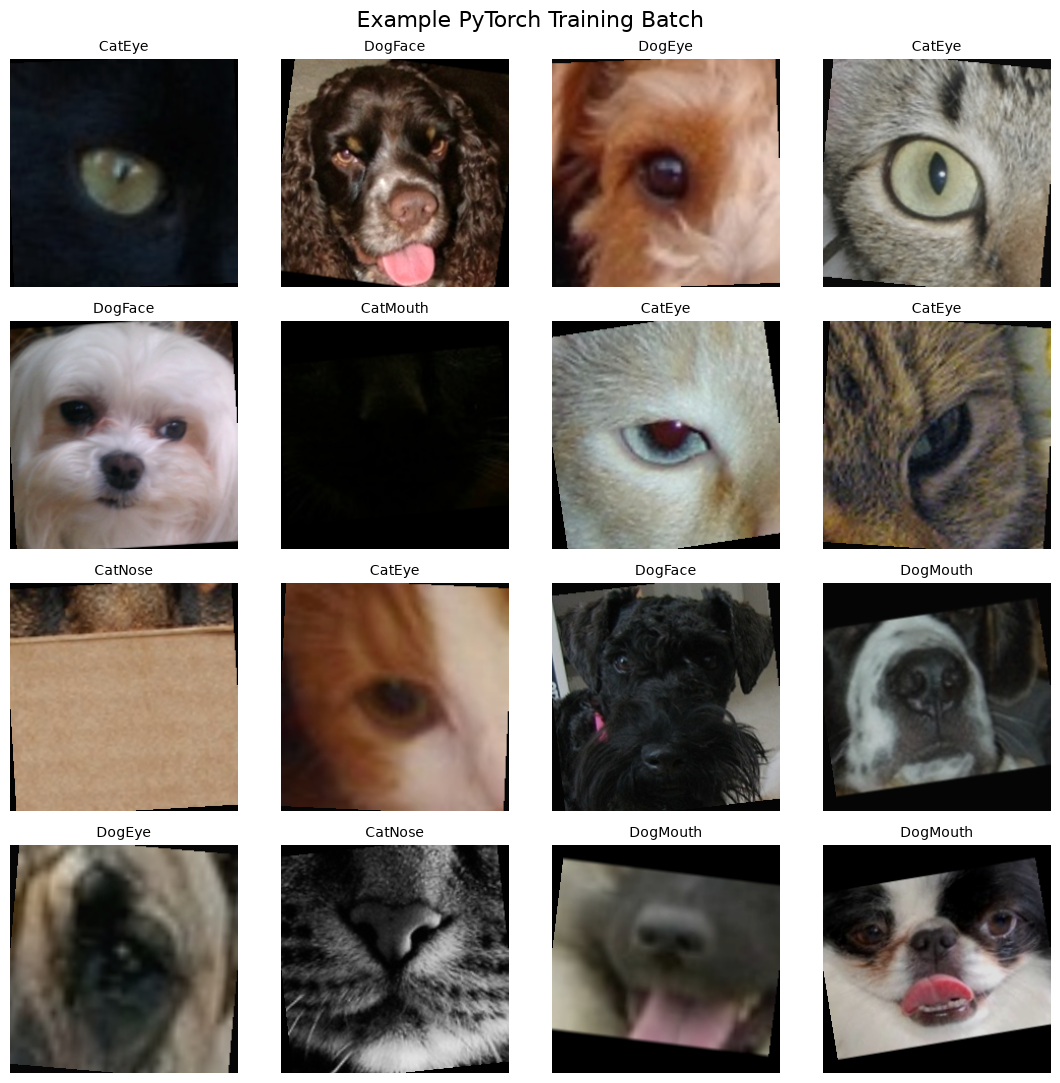

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_10_training_batch.png


In [21]:
# Shows the images and class labels from one training batch
IMAGES_TO_DISPLAY = min(16, len(batch_images))

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(11, 11),
)

axes = axes.flatten()

for index, axis in enumerate(axes):
    axis.axis("off")

    if index >= IMAGES_TO_DISPLAY:
        continue

    display_image = tensor_to_display_image(
        batch_images[index]
    )

    class_name = INDEX_TO_CLASS[
        int(batch_labels[index])
    ]

    axis.imshow(display_image)
    axis.set_title(class_name, fontsize=10)

plt.suptitle(
    "Example PyTorch Training Batch",
    fontsize=16,
)

plt.tight_layout()

batch_figure_path = (
    FIGURE_DIR
    / "figure_10_training_batch.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    batch_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", batch_figure_path)

## 21. Verify Test Order Without Inspecting Test Images

The competition test images must remain in the same order as `sample_submission.csv`.

The following checks use IDs and filenames only. Test images are not displayed, manually labelled, or used to select preprocessing settings.

In [22]:
# Checks the test identifiers without displaying the test images
test_dataset_ids = (
    test_dataset.dataframe["image_id"]
    .astype("string")
    .tolist()
)

submission_ids = (
    sample_submission["image_id"]
    .astype("string")
    .tolist()
)

test_order_matches = (
    test_dataset_ids == submission_ids
)

all_test_files_exist = all(
    (TEST_IMAGE_DIR / filename).exists()
    for filename in sample_submission["filename"]
)

print("Test dataset rows:", f"{len(test_dataset):,}")
print(
    "Sample-submission rows:",
    f"{len(sample_submission):,}",
)
print(
    "Test IDs match sample-submission order:",
    test_order_matches,
)
print(
    "All required test files exist:",
    all_test_files_exist,
)

assert test_order_matches
assert all_test_files_exist

Test dataset rows: 29,443
Sample-submission rows: 29,443
Test IDs match sample-submission order: True
All required test files exist: True


## 22. Save the Preprocessing Configuration

The main preprocessing choices are saved in a JSON file.

This makes the pipeline easier to reproduce and ensures later notebooks use the same:

- random seed;
- image size;
- batch size;
- class order;
- normalisation values;
- and augmentation settings.

In [23]:
# Saves preprocessing settings so later notebooks can reuse them
preprocessing_configuration = {
    "random_seed": RANDOM_SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "validation_fraction": VALIDATION_FRACTION,
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "normalisation_mean": IMAGENET_MEAN,
    "normalisation_std": IMAGENET_STD,
    "square_padding": True,
    "training_augmentation": {
        "horizontal_flip_probability": 0.5,
        "maximum_rotation_degrees": 10,
        "brightness_change": 0.15,
        "contrast_change": 0.15,
        "saturation_change": 0.10,
    },
    "validation_random_augmentation": False,
    "test_random_augmentation": False,
    "num_workers": NUM_WORKERS,
}

configuration_path = (
    PREPROCESSING_OUTPUT_DIR
    / "preprocessing_config.json"
)

with open(configuration_path, "w") as configuration_file:
    json.dump(
        preprocessing_configuration,
        configuration_file,
        indent=4,
    )

print("Configuration saved to:", configuration_path)

Configuration saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/preprocessing/preprocessing_config.json


## 23. Create the Preprocessing Summary

This table records the main pipeline decisions and their reasons.

It can be used as evidence when writing Task 2 of the report.

In [24]:
# Saves a readable summary of the preprocessing pipeline
preprocessing_summary = pd.DataFrame(
    {
        "pipeline_step": [
            "Colour conversion",
            "Shape handling",
            "Image resizing",
            "Label encoding",
            "Development split",
            "Duplicate protection",
            "Training augmentation",
            "Validation augmentation",
            "Test augmentation",
            "Normalisation",
            "Batch loading",
            "Random seed",
        ],
        "decision": [
            "Convert every opened image to RGB",
            "Pad the shorter sides to create a square",
            f"Resize to {IMAGE_SIZE} × {IMAGE_SIZE}",
            "Fixed mapping from eight class names to 0–7",
            (
                f"Approximately {100 * (1 - VALIDATION_FRACTION):.0f}% "
                f"training and {100 * VALIDATION_FRACTION:.0f}% validation"
            ),
            "Keep exact duplicate groups in one subset",
            (
                "Horizontal flip, small rotation, and "
                "small colour changes"
            ),
            "No random augmentation",
            "No random augmentation",
            "ImageNet mean and standard deviation",
            f"PyTorch DataLoader with batch size {BATCH_SIZE}",
            str(RANDOM_SEED),
        ],
        "reason": [
            "Provide three consistent colour channels",
            "Preserve image proportions before resizing",
            "Provide one input size for both planned CNN models",
            "Provide numerical targets for the CNN",
            "Create an unseen labelled validation subset",
            "Prevent duplicate leakage between subsets",
            "Improve robustness to normal visual variation",
            "Keep validation results fair and repeatable",
            "Keep final prediction processing repeatable",
            "Match the expected input for pretrained ResNet18",
            "Load images efficiently in manageable groups",
            "Make the split and experiments reproducible",
        ],
    }
)

display(preprocessing_summary)

# Saves the table as a CSV file for later notebooks or report evidence
preprocessing_summary.to_csv(
    PREPROCESSING_OUTPUT_DIR
    / "preprocessing_summary.csv",
    index=False,
)

,pipeline_step,decision,reason
0,Colour conversion,Convert every opened image to RGB,Provide three consistent colour channels
1,Shape handling,Pad the shorter sides to create a square,Preserve image proportions before resizing
2,Image resizing,Resize to 224 × 224,Provide one input size for both planned CNN mo...
3,Label encoding,Fixed mapping from eight class names to 0–7,Provide numerical targets for the CNN
4,Development split,Approximately 80% training and 20% validation,Create an unseen labelled validation subset
5,Duplicate protection,Keep exact duplicate groups in one subset,Prevent duplicate leakage between subsets
6,Training augmentation,"Horizontal flip, small rotation, and small col...",Improve robustness to normal visual variation
7,Validation augmentation,No random augmentation,Keep validation results fair and repeatable
8,Test augmentation,No random augmentation,Keep final prediction processing repeatable
9,Normalisation,ImageNet mean and standard deviation,Match the expected input for pretrained ResNet18


## 24. Final Pipeline Checks

The final checks confirm that:

- the original files still exist;
- all labelled images belong to one development subset;
- no image ID is shared between training and validation;
- no exact duplicate group is shared between training and validation;
- every class appears in both subsets;
- images are converted into tensors with shape `[3, 224, 224]`;
- validation processing is repeatable;
- and test IDs remain in Kaggle submission order.

In [25]:
# Checks that the prepared datasets and saved evidence are consistent
final_checks = pd.DataFrame(
    {
        "check": [
            "Original training CSV still exists",
            "Original sample-submission CSV still exists",
            "Original training image folder still exists",
            "Original test image folder still exists",
            "Training and validation cover all labelled images",
            "Shared image IDs across development subsets",
            "Shared duplicate groups across development subsets",
            "Every class appears in training",
            "Every class appears in validation",
            "Training batch has three colour channels",
            "Training batch uses 224 × 224 images",
            "Validation processing is deterministic",
            "Test order matches sample submission",
        ],
        "result": [
            TRAIN_LABELS_PATH.exists(),
            SAMPLE_SUBMISSION_PATH.exists(),
            TRAIN_IMAGE_DIR.exists(),
            TEST_IMAGE_DIR.exists(),
            all_images_accounted_for,
            len(shared_image_ids),
            len(shared_group_ids),
            training_classes == expected_classes,
            validation_classes == expected_classes,
            batch_images.shape[1] == 3,
            tuple(batch_images.shape[2:]) == (
                IMAGE_SIZE,
                IMAGE_SIZE,
            ),
            validation_difference == 0,
            test_order_matches,
        ],
        "expected": [
            True,
            True,
            True,
            True,
            True,
            0,
            0,
            True,
            True,
            True,
            True,
            True,
            True,
        ],
    }
)

display(final_checks)

# Saves the table as a CSV file for later notebooks or report evidence
final_checks.to_csv(
    PREPROCESSING_OUTPUT_DIR / "final_pipeline_checks.csv",
    index=False,
)

,check,result,expected
0,Original training CSV still exists,True,True
1,Original sample-submission CSV still exists,True,True
2,Original training image folder still exists,True,True
3,Original test image folder still exists,True,True
4,Training and validation cover all labelled images,True,True
5,Shared image IDs across development subsets,0,0
6,Shared duplicate groups across development sub...,0,0
7,Every class appears in training,True,True
8,Every class appears in validation,True,True
9,Training batch has three colour channels,True,True
